In [ ]:
# ── Cell 1 · Kaggle credentials & dataset download ───────────────────────────
import os
from google.colab import files

print("Upload your kaggle.json (from kaggle.com/settings → API → Create New Token)")
uploaded = files.upload()          # opens file picker

os.makedirs('/root/.kaggle', exist_ok=True)
with open('/root/.kaggle/kaggle.json', 'wb') as f:
    f.write(uploaded['kaggle.json'])
os.chmod('/root/.kaggle/kaggle.json', 0o600)

print("\nDownloading dataset...")
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia -p /content --quiet
!unzip -q /content/chest-xray-pneumonia.zip -d /content/data
print("Done.")

Upload your kaggle.json (from kaggle.com/settings → API → Create New Token)


Saving kaggle.json to kaggle.json

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
KGAT_fdfa1eb7d4723d888b828c77452c6802
Done.


In [ ]:
# ── Cell 2 · Verify dataset layout ───────────────────────────────────────────
import pathlib

DATA_DIR = pathlib.Path('/content/data/chest_xray')
for split in ['train', 'val', 'test']:
    for cls in ['NORMAL', 'PNEUMONIA']:
        p = DATA_DIR / split / cls
        if p.exists():
            print(f"{split}/{cls}: {len(list(p.iterdir()))} images")

train/NORMAL: 1341 images
train/PNEUMONIA: 3875 images
val/NORMAL: 8 images
val/PNEUMONIA: 8 images
test/NORMAL: 234 images
test/PNEUMONIA: 390 images


In [13]:
# ── Cell 3 · Fix val split (official val/ has only 16 images) ────────────────
import shutil, random

random.seed(42)
VAL_FRACTION = 0.10
CLASSES = ['NORMAL', 'PNEUMONIA']

for cls in CLASSES:
    src = DATA_DIR / 'train' / cls
    dst = DATA_DIR / 'val2' / cls
    dst.mkdir(parents=True, exist_ok=True)

    files_list = [f for f in src.iterdir() if not f.name.startswith('.')]
    random.shuffle(files_list)
    n_val = int(VAL_FRACTION * len(files_list))

    for f in files_list[:n_val]:
        shutil.move(str(f), str(dst / f.name))

    print(f"[{cls}] moved {n_val} → val2/{cls}/  (train left: {len(list(src.iterdir()))})")

print("\nFinal split counts:")
for split in ['train', 'val2', 'test']:
    for cls in CLASSES:
        p = DATA_DIR / split / cls
        if p.exists():
            print(f"  {split}/{cls}: {len(list(p.iterdir()))}")

[NORMAL] moved 120 → val2/NORMAL/  (train left: 1087)
[PNEUMONIA] moved 348 → val2/PNEUMONIA/  (train left: 3140)

Final split counts:
  train/NORMAL: 1087
  train/PNEUMONIA: 3140
  val2/NORMAL: 254
  val2/PNEUMONIA: 735
  test/NORMAL: 234
  test/PNEUMONIA: 390


In [ ]:
# ── Cell 4 · Imports & config ─────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve
)

print(f"TensorFlow {tf.__version__}")
print(f"GPU: {tf.config.list_physical_devices('GPU')}")

IMG_SIZE   = (224, 224)
BATCH_SIZE = 32
AUTOTUNE   = tf.data.AUTOTUNE
MODEL_DIR  = '/content/models'
os.makedirs(MODEL_DIR, exist_ok=True)

TensorFlow 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ── Cell 5 · Data pipeline ────────────────────────────────────────────────────
def load_split(split, shuffle=True):
    return tf.keras.utils.image_dataset_from_directory(
        str(DATA_DIR / split),
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode='binary',
        seed=42,
        shuffle=shuffle,
    )

train_ds = load_split('train')
val_ds   = load_split('val2')
test_ds  = load_split('test', shuffle=False)

CLASS_NAMES = train_ds.class_names
print(f"Classes: {CLASS_NAMES}")

# Augmentation (training only)
data_aug = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name='augmentation')

train_ds_aug = train_ds.map(
    lambda x, y: (data_aug(x, training=True), y),
    num_parallel_calls=AUTOTUNE,
).prefetch(AUTOTUNE)

val_ds  = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

# Class weights for imbalance (~3:1 PNEUMONIA:NORMAL)
train_labels = np.concatenate([y.numpy() for _, y in train_ds]).flatten().astype(int)
neg, pos = np.bincount(train_labels)
total = neg + pos
class_weight = {0: total / (2.0 * neg), 1: total / (2.0 * pos)}
print(f"Class weights → NORMAL: {class_weight[0]:.3f}  PNEUMONIA: {class_weight[1]:.3f}")

Found 4695 files belonging to 2 classes.
Found 521 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']
Class weights → NORMAL: 1.945  PNEUMONIA: 0.673


In [ ]:
# ── Cell 6 · Model architecture ───────────────────────────────────────────────
def build_model():
    base = MobileNetV2(
        input_shape=IMG_SIZE + (3,),
        include_top=False,
        weights='imagenet',
    )
    base.trainable = False

    inputs = tf.keras.Input(shape=IMG_SIZE + (3,), name='image_input')
    x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(1, activation='sigmoid', name='output')(x)

    return Model(inputs, outputs, name='pneumonia_classifier'), base

model, base_model = build_model()
model.summary(line_length=80)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "pneumonia_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)          │ (None, 224, 224, 3)      │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ true_divide (TrueDivide)          │ (None, 224, 224, 3)      │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ subtract (Subtract)               │ (None, 224, 224, 3)      │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224 (Functional) │ (None, 7, 7, 1280)       │     2,257,984 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)      │ (None, 1280)             │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout (Dropout)                 │ (None, 1280)             │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense (Dense)                     │ (None, 128)              │       163,968 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout_1 (Dropout)               │ (None, 128)              │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ output (Dense)                    │ (None, 1)                │           129 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# ── Cell 7 · Phase 1 — Train head only (backbone frozen) ─────────────────────
METRICS = [
    'accuracy',
    tf.keras.metrics.Precision(name='precision'),
    tf.keras.metrics.Recall(name='recall'),
    tf.keras.metrics.AUC(name='auc'),
]

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='binary_crossentropy',
    metrics=METRICS,
)

cb1 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(
        f'{MODEL_DIR}/best_phase1.keras', save_best_only=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.CSVLogger(f'{MODEL_DIR}/history_phase1.csv'),
]

print("═"*60)
print("  PHASE 1 — Classification head only (backbone frozen)")
print("═"*60)

history1 = model.fit(
    train_ds_aug,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weight,
    callbacks=cb1,
)

════════════════════════════════════════════════════════════
  PHASE 1 — Classification head only (backbone frozen)
════════════════════════════════════════════════════════════
Epoch 1/15
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 550ms/step - accuracy: 0.8140 - auc: 0.8975 - loss: 0.3842 - precision: 0.9278 - recall: 0.8037
Epoch 1: val_loss improved from None to 0.15935, saving model to /content/models/best_phase1.keras

Epoch 1: finished saving model to /content/models/best_phase1.keras
147/147 ━━━━━━━━━━━━━━━━━━━━ 125s 693ms/step - accuracy: 0.8846 - auc: 0.9578 - loss: 0.2615 - precision: 0.9609 - recall: 0.8804 - val_accuracy: 0.9443 - val_auc: 0.9779 - val_loss: 0.1594 - val_precision: 0.9812 - val_recall: 0.9432 - learning_rate: 0.0010
Epoch 2/15
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 472ms/step - accuracy: 0.9247 - auc: 0.9808 - loss: 0.1754 - precision: 0.9756 - recall: 0.9202
Epoch 2: val_loss improved from 0.15935 to 0.15765, saving model to /content/models/best_phase1.keras

Epoch 2: finish

In [ ]:
# ── Cell 8 · Phase 2 — Fine-tune top-30 backbone layers ──────────────────────
base_model.trainable = True
fine_tune_at = len(base_model.layers) - 30
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

trainable = sum(1 for l in base_model.layers if l.trainable)
print(f"Trainable backbone layers: {trainable}/{len(base_model.layers)}")

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='binary_crossentropy',
    metrics=METRICS,
)

cb2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(
        f'{MODEL_DIR}/best_final.keras', save_best_only=True, verbose=1),
    tf.keras.callbacks.CSVLogger(f'{MODEL_DIR}/history_phase2.csv'),
]

print("═"*60)
print("  PHASE 2 — Fine-tuning top MobileNetV2 layers")
print("═"*60)

history2 = model.fit(
    train_ds_aug,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weight,
    callbacks=cb2,
)

model.save(f'{MODEL_DIR}/pneumonia_mobilenetv2_final.keras')
print(f"\nModel saved → {MODEL_DIR}/pneumonia_mobilenetv2_final.keras")

Trainable backbone layers: 30/154
════════════════════════════════════════════════════════════
  PHASE 2 — Fine-tuning top MobileNetV2 layers
════════════════════════════════════════════════════════════
Epoch 1/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 500ms/step - accuracy: 0.8827 - auc: 0.9620 - loss: 0.4924 - precision: 0.9177 - recall: 0.9603
Epoch 1: val_loss improved from None to 0.13756, saving model to /content/models/best_final.keras

Epoch 1: finished saving model to /content/models/best_final.keras
147/147 ━━━━━━━━━━━━━━━━━━━━ 107s 587ms/step - accuracy: 0.9135 - auc: 0.9670 - loss: 0.2913 - precision: 0.9424 - recall: 0.9463 - val_accuracy: 0.9559 - val_auc: 0.9844 - val_loss: 0.1376 - val_precision: 0.9619 - val_recall: 0.9793
Epoch 2/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 473ms/step - accuracy: 0.9359 - auc: 0.9858 - loss: 0.1556 - precision: 0.9756 - recall: 0.9361
Epoch 2: val_loss improved from 0.13756 to 0.13353, saving model to /content/models/best_final.keras

Epoch 2: finishe

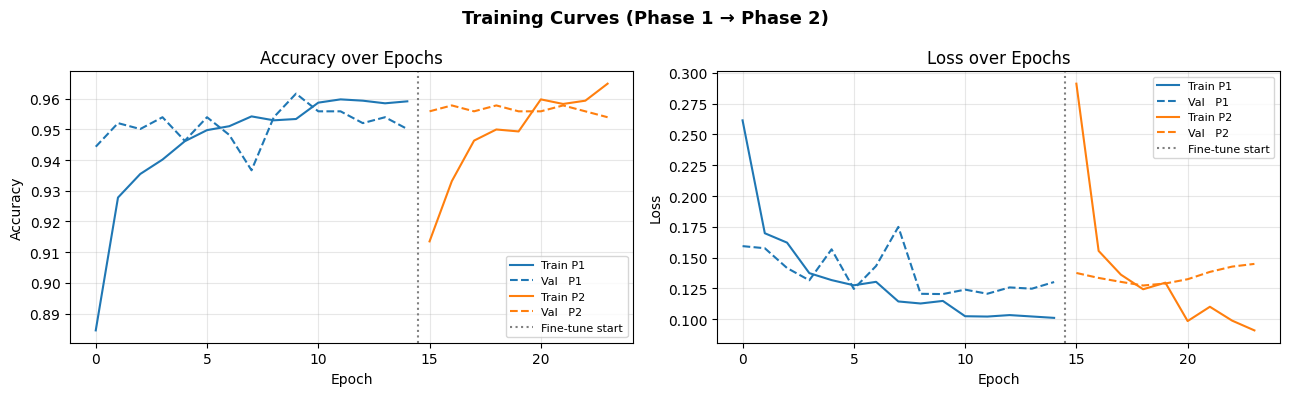

In [ ]:
# ── Cell 9 · Training curves ──────────────────────────────────────────────────
import pandas as pd

h1 = pd.read_csv(f'{MODEL_DIR}/history_phase1.csv')
h2 = pd.read_csv(f'{MODEL_DIR}/history_phase2.csv')
offset = len(h1)
h2_ep  = h2['epoch'] + offset

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('Training Curves (Phase 1 → Phase 2)', fontsize=13, fontweight='bold')

for ax, (train_m, val_m), title in zip(
    axes,
    [('accuracy', 'val_accuracy'), ('loss', 'val_loss')],
    ['Accuracy', 'Loss']
):
    ax.plot(h1['epoch'], h1[train_m],  label='Train P1', color='#1f77b4')
    ax.plot(h1['epoch'], h1[val_m],    label='Val   P1', color='#1f77b4', linestyle='--')
    ax.plot(h2_ep,       h2[train_m],  label='Train P2', color='#ff7f0e')
    ax.plot(h2_ep,       h2[val_m],    label='Val   P2', color='#ff7f0e', linestyle='--')
    ax.axvline(x=offset - 0.5, color='gray', linestyle=':', lw=1.5, label='Fine-tune start')
    ax.set_xlabel('Epoch'); ax.set_ylabel(title)
    ax.set_title(f'{title} over Epochs'); ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{MODEL_DIR}/training_curves.png', dpi=150)
plt.show()

In [14]:
# ── Cell 10 · Test-set evaluation ────────────────────────────────────────────
y_true      = np.concatenate([y.numpy() for _, y in test_ds]).flatten()
y_pred_prob = model.predict(test_ds, verbose=1).flatten()
y_pred      = (y_pred_prob > 0.5).astype(int)

accuracy = (y_pred == y_true).mean()
auc      = roc_auc_score(y_true, y_pred_prob)

print("\n" + "═"*55)
print(f"  Test Accuracy : {accuracy * 100:.2f} %")
print(f"  ROC-AUC       : {auc:.4f}")
print("═"*55)
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 325ms/step

═══════════════════════════════════════════════════════
  Test Accuracy : 84.78 %
  ROC-AUC       : 0.9657
═══════════════════════════════════════════════════════

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.97      0.61      0.75       234
   PNEUMONIA       0.81      0.99      0.89       390

    accuracy                           0.85       624
   macro avg       0.89      0.80      0.82       624
weighted avg       0.87      0.85      0.84       624



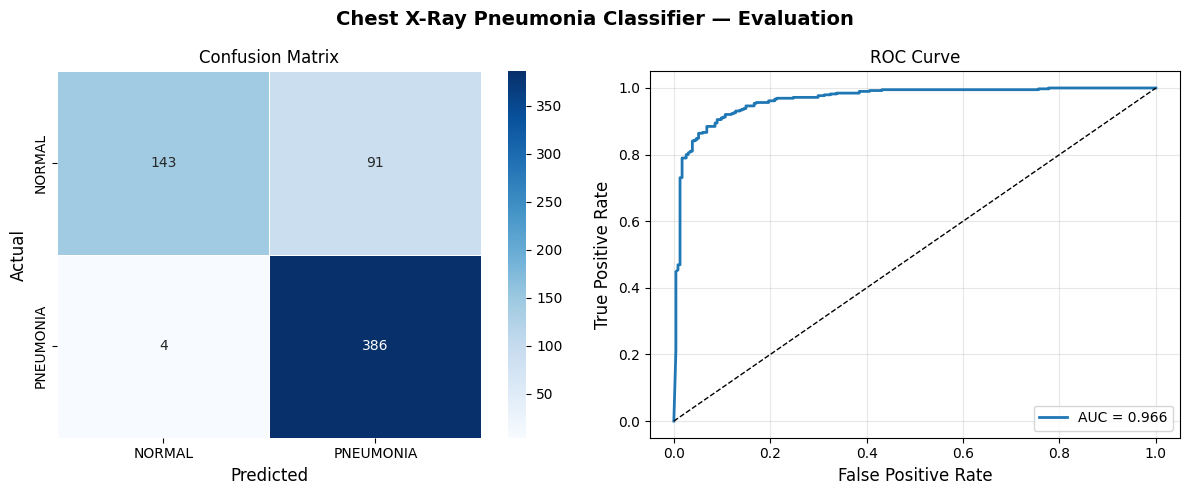

Plots saved to /content/models/


In [ ]:
# ── Cell 11 · Confusion matrix + ROC curve ────────────────────────────────────
cm = confusion_matrix(y_true, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Chest X-Ray Pneumonia Classifier — Evaluation', fontsize=14, fontweight='bold')

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    ax=axes[0], linewidths=0.5,
)
axes[0].set_xlabel('Predicted', fontsize=12)
axes[0].set_ylabel('Actual', fontsize=12)
axes[0].set_title('Confusion Matrix')

fpr, tpr, _ = roc_curve(y_true, y_pred_prob)
axes[1].plot(fpr, tpr, lw=2, label=f'AUC = {auc:.3f}', color='#1f77b4')
axes[1].plot([0,1],[0,1],'k--', lw=1)
axes[1].set_xlabel('False Positive Rate', fontsize=12)
axes[1].set_ylabel('True Positive Rate', fontsize=12)
axes[1].set_title('ROC Curve')
axes[1].legend(loc='lower right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{MODEL_DIR}/confusion_matrix.png', dpi=150)
plt.show()
print(f"Plots saved to {MODEL_DIR}/")

In [15]:
# ── Cell 12 · Download trained model & plots ──────────────────────────────────
from google.colab import files
import zipfile

zip_path = '/content/pneumonia_results.zip'
with zipfile.ZipFile(zip_path, 'w') as z:
    for fname in [
        'pneumonia_mobilenetv2_final.keras',
        'best_final.keras',
        'confusion_matrix.png',
        'training_curves.png',
        'history_phase1.csv',
        'history_phase2.csv',
    ]:
        fpath = f'{MODEL_DIR}/{fname}'
        if os.path.exists(fpath):
            z.write(fpath, fname)

print("Downloading results zip...")
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>